# Notebook 2 — PyTorch for Biologists (with scikit-learn comparison)
This notebook introduces **PyTorch** for biology students.

You will learn:
- tensors and devices (CPU/GPU)
- `Dataset` and `DataLoader`
- defining a model (`nn.Module`)
- training loop: forward → loss → backward → optimizer step
- evaluation: accuracy + ROC‑AUC
- saving/loading a model

We use the breast cancer dataset and compare to a scikit‑learn logistic regression baseline.

## References (official docs)
- Datasets & DataLoaders: https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html
- Training: https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html
- Autograd: https://docs.pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html


In [1]:
# If needed:
# pip install torch numpy matplotlib scikit-learn

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, RocCurveDisplay

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

## 1) Load + split data (train/val/test) and scale using TRAIN only

In [2]:
data = load_breast_cancer()
X = data.data.astype(np.float32)
y = data.target.astype(np.int64)

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.2, random_state=42, stratify=y_trainval
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val   = scaler.transform(X_val).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)

X_train.shape, X_val.shape, X_test.shape


((364, 30), (91, 30), (114, 30))

## 2) scikit‑learn baseline

sklearn test accuracy: 0.9824561403508771
sklearn test ROC-AUC:   0.9957010582010581


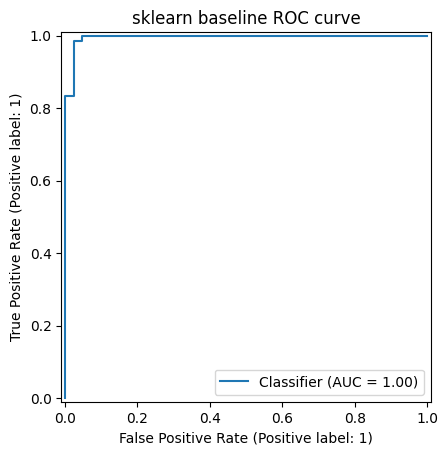

In [3]:
sk_model = LogisticRegression(max_iter=5000)
sk_model.fit(X_train, y_train)
proba = sk_model.predict_proba(X_test)[:,1]
pred = (proba >= 0.5).astype(int)

print("sklearn test accuracy:", accuracy_score(y_test, pred))
print("sklearn test ROC-AUC:  ", roc_auc_score(y_test, proba))

RocCurveDisplay.from_predictions(y_test, proba)
plt.title("sklearn baseline ROC curve")
plt.show()


## 3) PyTorch Dataset + DataLoader

In [4]:
class NumpyDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)  # float32
        self.y = torch.from_numpy(y)  # int64
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = NumpyDataset(X_train, y_train)
val_ds   = NumpyDataset(X_val, y_val)
test_ds  = NumpyDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=128, shuffle=False)

xb, yb = next(iter(train_loader))
xb.shape, yb.shape, xb.dtype, yb.dtype


(torch.Size([64, 30]), torch.Size([64]), torch.float32, torch.int64)

## 4) Define a simple neural network (MLP)

In [5]:
class MLP(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)  # logits for 2 classes
        )
    def forward(self, x):
        return self.net(x)

model = MLP(n_in=X_train.shape[1]).to(device)
model


MLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
)

## 5) Training loop

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)

        if train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(train):
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * xb.size(0)
        pred = torch.argmax(logits, dim=1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)

    return total_loss/total, correct/total

history = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}

for epoch in range(1, 31):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    if epoch in [1,2,3,5,10,20,30]:
        print(f"epoch {epoch:02d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")


epoch 01 | train loss 0.673 acc 0.580 | val loss 0.624 acc 0.956
epoch 02 | train loss 0.598 acc 0.915 | val loss 0.553 acc 0.967
epoch 03 | train loss 0.519 acc 0.937 | val loss 0.470 acc 0.967
epoch 05 | train loss 0.338 acc 0.948 | val loss 0.295 acc 0.956
epoch 10 | train loss 0.112 acc 0.962 | val loss 0.110 acc 0.967
epoch 20 | train loss 0.046 acc 0.992 | val loss 0.068 acc 0.978
epoch 30 | train loss 0.025 acc 0.995 | val loss 0.068 acc 0.978


### Plot learning curves

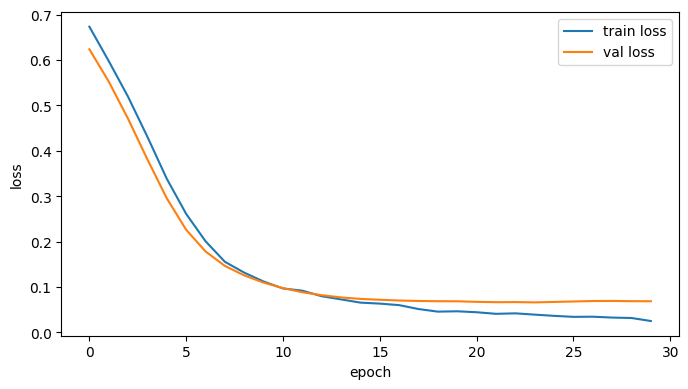

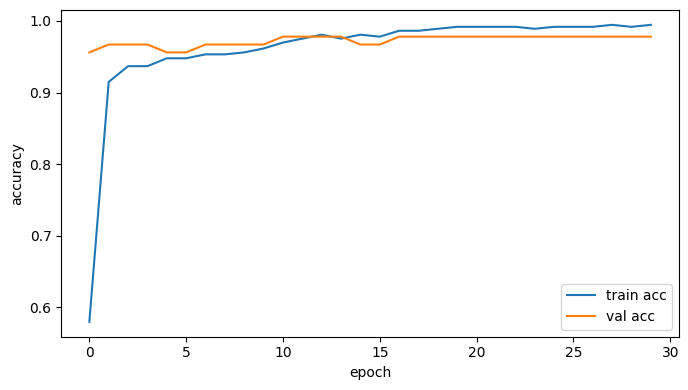

In [7]:
plt.figure(figsize=(7,4))
plt.plot(history["train_loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4))
plt.plot(history["train_acc"], label="train acc")
plt.plot(history["val_acc"], label="val acc")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.tight_layout(); plt.show()


## 6) Test evaluation (accuracy + ROC‑AUC)

PyTorch test accuracy: 0.9649122807017544
PyTorch test ROC-AUC:   0.9937169312169313


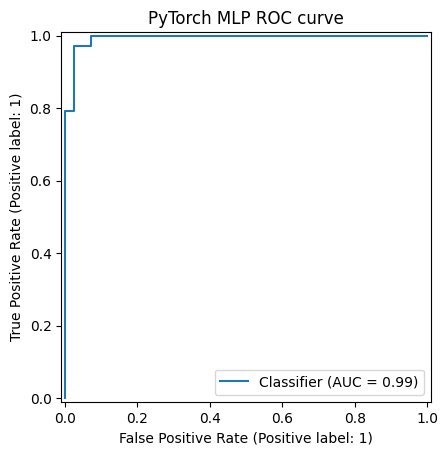

In [8]:
@torch.no_grad()
def predict_proba(loader):
    model.eval()
    probs_all, y_all = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        logits = model(xb)
        probs = torch.softmax(logits, dim=1)[:,1].cpu().numpy()
        probs_all.append(probs)
        y_all.append(yb.numpy())
    return np.concatenate(probs_all), np.concatenate(y_all)

probs, ytrue = predict_proba(test_loader)
pred = (probs >= 0.5).astype(int)

print("PyTorch test accuracy:", accuracy_score(ytrue, pred))
print("PyTorch test ROC-AUC:  ", roc_auc_score(ytrue, probs))

RocCurveDisplay.from_predictions(ytrue, probs)
plt.title("PyTorch MLP ROC curve")
plt.show()


## 7) Save / load model weights

In [9]:
save_path = "mlp_breast_cancer_state_dict.pt"
torch.save(model.state_dict(), save_path)
print("Saved:", save_path)

model2 = MLP(n_in=X_train.shape[1]).to(device)
model2.load_state_dict(torch.load(save_path, map_location=device))
model2.eval()

@torch.no_grad()
def first_batch_probs(m):
    xb, _ = next(iter(test_loader))
    xb = xb.to(device)
    return torch.softmax(m(xb), dim=1)[:,1].cpu().numpy()

p1 = first_batch_probs(model)
p2 = first_batch_probs(model2)
print("max|diff|:", float(np.max(np.abs(p1 - p2))))


Saved: mlp_breast_cancer_state_dict.pt
max|diff|: 0.0


## 8) Where PyTorch is especially useful in biology
- Custom architectures (CNNs for microscopy, Transformers for sequences)
- Multi‑modal models (omics + imaging + clinical metadata)
- Transfer learning and pretrained models
- GPU acceleration for large datasets
